In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/shree1992/housedata/output.csv
/kaggle/input/datasets/shree1992/housedata/data.csv
/kaggle/input/datasets/shree1992/housedata/data.dat


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
df=pd.read_csv("/kaggle/input/datasets/shree1992/housedata/data.csv")
df.info()
df.head()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   object 
 17  country        4600 non-null   object 
dtypes: float

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [4]:
#missing value check
print(df.isnull().sum())
#duplicate value check
print(df.duplicated().sum())

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64
0


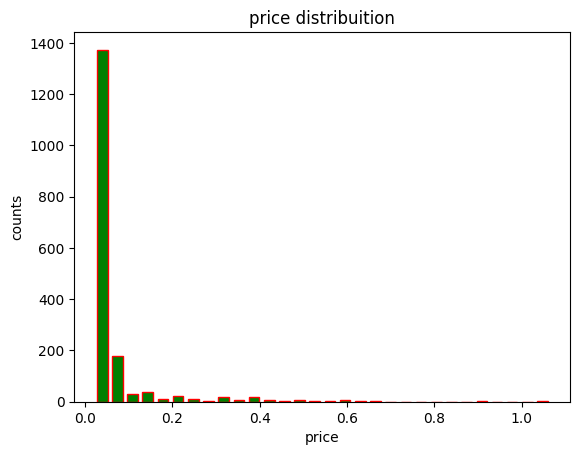

In [5]:
#price analysis
counts=df["price"].value_counts(normalize=True)*100
counts.plot(kind="hist",bins=30,color="g",edgecolor="r",align="mid",rwidth=0.7)
plt.xlabel("price")
plt.ylabel("counts")
plt.title("price distribuition")
plt.show()
#most houses fall within a lower price
#A few houses have extreamly high prices
#the price distribuition is positively skewed
#possible outliers exist in the data set

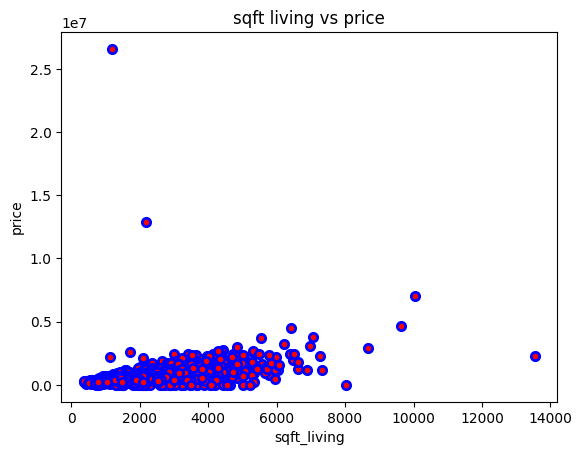

In [6]:
#sqft_living vs price
plt.scatter(df["sqft_living"],df["price"],color="r",edgecolor="b",linewidth=2)
plt.xlabel("sqft_living")
plt.ylabel("price")
plt.title("sqft living vs price")
plt.show()
#there is a positive relationship between price and living area
#house with larger living spaces generally have higher price


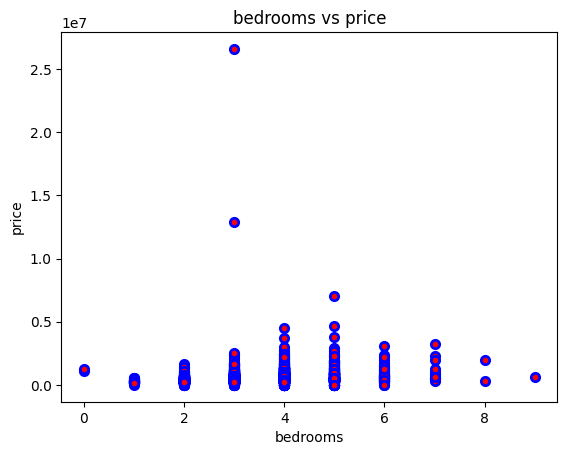

In [7]:
#bedrooms vs price
plt.scatter(df["bedrooms"],df["price"],color="r",edgecolor="b",linewidth=2)
plt.xlabel("bedrooms")
plt.ylabel("price")
plt.title("bedrooms vs price")
plt.show()
#most houses have 3 to 5 bedrooms
#house price generally increase with the number of bedrooms
#the relation between bedrooms vs price is modearte

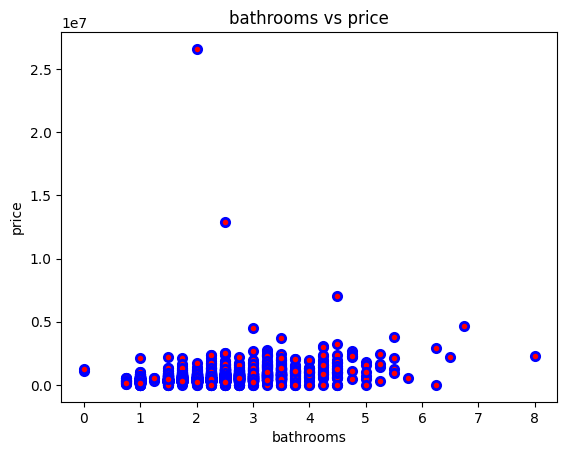

In [8]:
#barthrooms vs price analysis
plt.scatter(df["bathrooms"],df["price"],color="r",edgecolor="b",linewidth=2)
plt.xlabel("bathrooms")
plt.ylabel("price")
plt.title("bathrooms vs price")
plt.show()
#the graph shows that while more bathrooms are common in certain price brackets,they are not the primary driver of high prices


In [9]:
#waterfront vs price
print(df.groupby("waterfront")["price"].mean())
#condition vs price
print(df.groupby('condition')["price"].mean())
df.head()
#houses with waterfront views are significantly more expensive
#better conditioned houses tend to have higher average price

waterfront
0    5.454623e+05
1    1.451621e+06
Name: price, dtype: float64
condition
1    306633.333333
2    324373.750000
3    550111.516394
4    533647.286072
5    637041.322258
Name: price, dtype: float64


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


'The heatmap shows the relationship between different housing features.\nsqft_living, bathrooms, and bedrooms have strong positive correlations with house size and\nprice.\nsqft_above has the strongest correlation with sqft_living, indicating that most living space \ncomes from above-ground areas.\nSome variables like sqft_lot have weak correlations, meaning they do not strongly affect other\nfeatures.\nNegative correlations such as between condition and yr_built indicate inverse relationships\nbetween those variables'

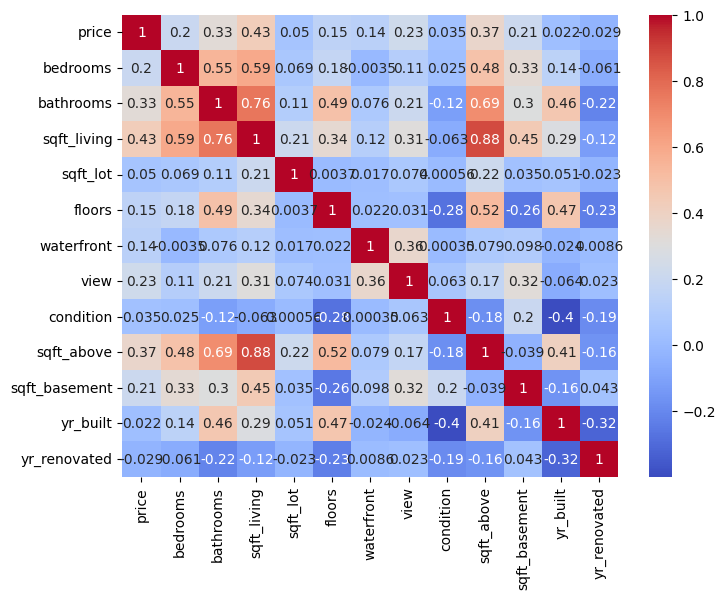

In [10]:
import seaborn as sns
corr=df.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.show
'''The heatmap shows the relationship between different housing features.
sqft_living, bathrooms, and bedrooms have strong positive correlations with house size and
price.
sqft_above has the strongest correlation with sqft_living, indicating that most living space 
comes from above-ground areas.
Some variables like sqft_lot have weak correlations, meaning they do not strongly affect other
features.
Negative correlations such as between condition and yr_built indicate inverse relationships
between those variables'''

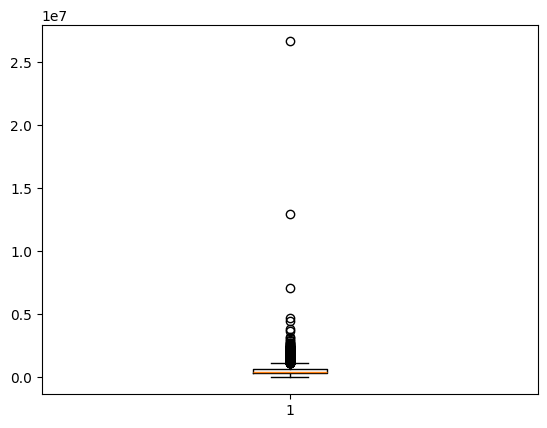

In [11]:
#outlier detection
plt.boxplot(df["price"])
plt.show()
#the price distribuition is heavily right-skewed with extreme outliers......

In [12]:
#date featuring
df["date"]=pd.to_datetime(df["date"])
df["year"]=df["date"].dt.year
df["month"]=df["date"].dt.month
print(df["date"])
print(df["year"])
print(df["month"])

0      2014-05-02
1      2014-05-02
2      2014-05-02
3      2014-05-02
4      2014-05-02
          ...    
4595   2014-07-09
4596   2014-07-09
4597   2014-07-09
4598   2014-07-10
4599   2014-07-10
Name: date, Length: 4600, dtype: datetime64[ns]
0       2014
1       2014
2       2014
3       2014
4       2014
        ... 
4595    2014
4596    2014
4597    2014
4598    2014
4599    2014
Name: year, Length: 4600, dtype: int32
0       5
1       5
2       5
3       5
4       5
       ..
4595    7
4596    7
4597    7
4598    7
4599    7
Name: month, Length: 4600, dtype: int32


In [13]:
#price per sqft
df["price_per_sqft"]=df["price"]/df["sqft_living"]
print(df[["price","sqft_living","price_per_sqft"]].head())

       price  sqft_living  price_per_sqft
0   313000.0         1340      233.582090
1  2384000.0         3650      653.150685
2   342000.0         1930      177.202073
3   420000.0         2000      210.000000
4   550000.0         1940      283.505155


In [14]:
#total rooms
df["total_rooms"]=df["bedrooms"]+df["bathrooms"]
print(df["total_rooms"])

0       4.50
1       7.50
2       5.00
3       5.25
4       6.50
        ... 
4595    4.75
4596    5.50
4597    5.50
4598    6.00
4599    5.50
Name: total_rooms, Length: 4600, dtype: float64


In [15]:
#living area ratio
df["living_ratio"]=df["sqft_living"]/df["sqft_lot"]
print(df["living_ratio"])

0       0.169363
1       0.403315
2       0.161547
3       0.249066
4       0.184762
          ...   
4595    0.237421
4596    0.192790
4597    0.429142
4598    0.315234
4599    0.183905
Name: living_ratio, Length: 4600, dtype: float64


In [16]:
df["waterfront"]=df["waterfront"].map({
    0:"No",
    1:"yes"
})
print(df["waterfront"])

0       No
1       No
2       No
3       No
4       No
        ..
4595    No
4596    No
4597    No
4598    No
4599    No
Name: waterfront, Length: 4600, dtype: object


R² Score: 0.026915972334419225
MAE: 212795.25164112152


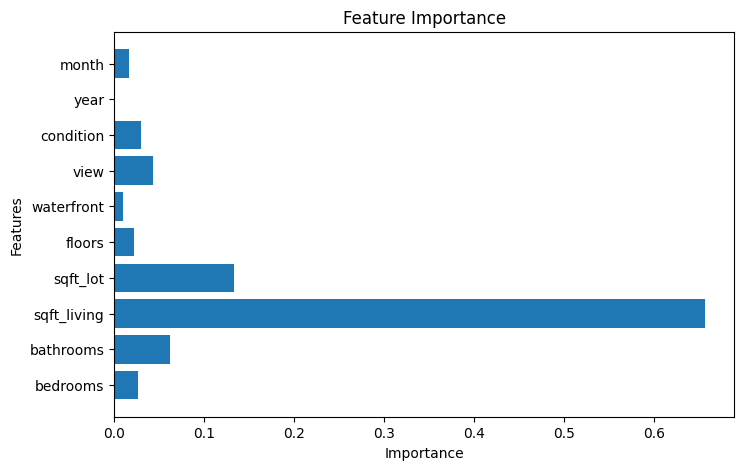

'The model shows poor predictive performance with an R² score of 0.0269 and a high MAE of\n212,795. This suggests that the current features are not sufficient to explain house price \nvariations, and additional relevant features are needed\n'

In [17]:
#covert into string to float
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])
    
# Step 1: Import libraries

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_absolute_error
import matplotlib.pyplot as plt

# Step 2: Missing value remove

df = df.dropna()

# Step 3: Date feature engineering

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# Step 4: Features and Target

X = df[['bedrooms',
        'bathrooms',
        'sqft_living',
        'sqft_lot',
        'floors',
        'waterfront',
        'view',
        'condition',
        'year',
        'month']]

y = df['price']

# Step 5: Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Step 6: Random Forest Model

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    random_state=42
)

# Step 7: Train Model

model.fit(X_train,y_train)

# Step 8: Prediction

y_pred = model.predict(X_test)

# Step 9: Model Evaluation

r2 = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)

print("R² Score:",r2)
print("MAE:",mae)

# Step 10: Feature Importance

importance = model.feature_importances_

plt.figure(figsize=(8,5))

plt.barh(X.columns,importance)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance")

plt.show()
'''The model shows poor predictive performance with an R² score of 0.0269 and a high MAE of
212,795. This suggests that the current features are not sufficient to explain house price 
variations, and additional relevant features are needed
'''

In [18]:
#business insights
'''1. Living area strongly influences house prices:
Houses with larger living areas tend to have higher prices, indicating that property size is
a key factor in determining market value.

2. Waterfront properties may have higher market value:
Properties located near waterfront areas generally tend to be priced higher because of better
views and location advantages.

3. House condition affects property value:
Well-maintained houses are expected to have better market prices compared to properties in
poor condition.
    
4. Bedrooms alone are not sufficient for price prediction:
The analysis suggests that simply increasing the number of bedrooms does not always lead 
to a significant increase in house price.

5. The current model shows weak predictive performance:
The low R² score (0.0269) indicates that the existing features explain only a small portion 
of house price variation.
    
6. High prediction error exists:
The model's average prediction error is approximately 212,795, suggesting that predicted prices differ substantially from actual prices.
7. Additional features are needed ,Including factors such as:
Location
Zip code
House age
Property grade
Latitude and longitude
may improve prediction performance.
    
8. Feature engineering can improve model accuracy:
Creating additional features from existing data may help capture hidden patterns and improve
model performance.'''

"1. Living area strongly influences house prices:\nHouses with larger living areas tend to have higher prices, indicating that property size is\na key factor in determining market value.\n\n2. Waterfront properties may have higher market value:\nProperties located near waterfront areas generally tend to be priced higher because of better\nviews and location advantages.\n\n3. House condition affects property value:\nWell-maintained houses are expected to have better market prices compared to properties in\npoor condition.\n    \n4. Bedrooms alone are not sufficient for price prediction:\nThe analysis suggests that simply increasing the number of bedrooms does not always lead \nto a significant increase in house price.\n\n5. The current model shows weak predictive performance:\nThe low R² score (0.0269) indicates that the existing features explain only a small portion \nof house price variation.\n    \n6. High prediction error exists:\nThe model's average prediction error is approximatel